From the notebook,Argo is a system of autonomous floats that are put into the ocean, floating around with the currents, and periodically does vertical sections to take in-situ measurements of things like temperature, salinity, pressure, and so forth down to about 2000 m depth. In which argo data are data of temperature, salinity, pressure collected from the system.

Meanwhile,TEOS-10 equation which stands for International Thermodynamic Equation of Seawater - 2010. The equation is built based on Gibbs function formulation from which thermodynamic properties such as entropy,potential temperature,enthalpy and potential enthalpy are calculated directly.The equation is vital for measuring ocean's role in exchanging heat with atmosphere and ice as it gives out concise number of enthalpy and entropy which helps to provides accurate description for advection and diffusion of heat in ocean interior.[(PDF) the international thermodynamic equation of seawater 2010 (TEOS-10): Calculation and use of thermodynamic properties. UNSCO Library . (2010). https://www.researchgate.net/publication/216028042_The_International_Thermodynamic_Equation_of_Seawater_2010_TEOS-10_Calculation_and_Use_of_Thermodynamic_Properties ]

In [ ]:
# sample code to load the numerical models

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# (slightly hacked) routine for computing TEOS-10 density
#   [I've forced p=0 because this is surface argo data we are dealing with]
def sigmai_dep(CT, SA, p=0):
    """
    Compute the in-situ (or potential) density from CONSERVATIVE Temperature,
    ABSOLUTE Salinity and pressure fields using the TEOS-10 EOS

    p can be a field (computed with subroutine p_from_z say) to get in-situ
    density or can be a number p = p_ref, then it is a potential density
    referenced to p_ref

    Adapted from the MATLAB GSW toolbox (http://www.TEOS-10.org)

    Inputs:
    CT             = Conservative Temperature      t        deg celsius
    SA             = Absolute Salinity             s        g / kg
    p              = (reference) pressure          p        dbar

    Returns:
    sigmai_dep_out = (potential density            rho      kg / m^3

    """
    # ensures that SA is non-negative.
    SA = abs(SA)

    # deltaS = 24
    sfac = 0.0248826675584615                 # sfac   = 1/(40*(35.16504/35)).
    offset = 5.971840214030754e-1             # offset = deltaS*sfac.

    x2 = sfac * SA
    xs = np.sqrt(x2 + offset)
    ys = CT * 0.025
    z  = p * 1e-4

    v000 =  1.0769995862e-3
    v001 = -6.0799143809e-5
    v002 =  9.9856169219e-6
    v003 = -1.1309361437e-6
    v004 =  1.0531153080e-7
    v005 = -1.2647261286e-8
    v006 =  1.9613503930e-9
    v010 = -1.5649734675e-5
    v011 =  1.8505765429e-5
    v012 = -1.1736386731e-6
    v013 = -3.6527006553e-7
    v014 =  3.1454099902e-7
    v020 =  2.7762106484e-5
    v021 = -1.1716606853e-5
    v022 =  2.1305028740e-6
    v023 =  2.8695905159e-7
    v030 = -1.6521159259e-5
    v031 =  7.9279656173e-6
    v032 = -4.6132540037e-7
    v040 =  6.9111322702e-6
    v041 = -3.4102187482e-6
    v042 = -6.3352916514e-8
    v050 = -8.0539615540e-7
    v051 =  5.0736766814e-7
    v060 =  2.0543094268e-7
    v100 = -3.1038981976e-4
    v101 =  2.4262468747e-5
    v102 = -5.8484432984e-7
    v103 =  3.6310188515e-7
    v104 = -1.1147125423e-7
    v110 =  3.5009599764e-5
    v111 = -9.5677088156e-6
    v112 = -5.5699154557e-6
    v113 = -2.7295696237e-7
    v120 = -3.7435842344e-5
    v121 = -2.3678308361e-7
    v122 =  3.9137387080e-7
    v130 =  2.4141479483e-5
    v131 = -3.4558773655e-6
    v132 =  7.7618888092e-9
    v140 = -8.7595873154e-6
    v141 =  1.2956717783e-6
    v150 = -3.3052758900e-7
    v200 =  6.6928067038e-4
    v201 = -3.4792460974e-5
    v202 = -4.8122251597e-6
    v203 =  1.6746303780e-8
    v210 = -4.3592678561e-5
    v211 =  1.1100834765e-5
    v212 =  5.4620748834e-6
    v220 =  3.5907822760e-5
    v221 =  2.9283346295e-6
    v222 = -6.5731104067e-7
    v230 = -1.4353633048e-5
    v231 =  3.1655306078e-7
    v240 =  4.3703680598e-6
    v300 = -8.5047933937e-4
    v301 =  3.7470777305e-5
    v302 =  4.9263106998e-6
    v310 =  3.4532461828e-5
    v311 = -9.8447117844e-6
    v312 = -1.3544185627e-6
    v320 = -1.8698584187e-5
    v321 = -4.8826139200e-7
    v330 =  2.2863324556e-6
    v400 =  5.8086069943e-4
    v401 = -1.7322218612e-5
    v402 = -1.7811974727e-6
    v410 = -1.1959409788e-5
    v411 =  2.5909225260e-6
    v420 =  3.8595339244e-6
    v500 = -2.1092370507e-4
    v501 =  3.0927427253e-6
    v510 =  1.3864594581e-6
    v600 =  3.1932457305e-5

    v = v000 + (
        xs * (v100 + xs * (v200 + xs * (v300 + xs * (v400 + xs * (v500
      + v600 * xs))))) + ys * (v010 + xs * (v110 + xs * (v210 + xs * (v310
      + xs * (v410 + v510 * xs)))) + ys * (v020 + xs * (v120 + xs * (v220
      + xs * (v320 + v420 * xs))) + ys * (v030 + xs * (v130 + xs * (v230
      + v330 * xs)) + ys * (v040 + xs * (v140 + v240*xs) + ys * (v050
      + v150 * xs + v060 * ys))))) + z * (v001 + xs * (v101 + xs * (v201
      + xs * (v301 + xs * (v401 + v501 * xs)))) + ys * (v011 + xs * (v111
      + xs * (v211 + xs * (v311 + v411 * xs))) + ys * (v021 + xs * (v121
      + xs * (v221 + v321 * xs)) + ys * (v031 + xs * (v131 + v231 * xs)
      + ys * (v041 + v141 * xs + v051 * ys)))) + z * (v002 + xs * (v102
      + xs * (v202 + xs * (v302 + v402 * xs))) + ys * (v012 + xs * (v112
      + xs * (v212 + v312 * xs)) + ys * (v022 + xs * (v122 + v222 * xs)
      + ys * (v032 + v132 * xs + v042 * ys))) + z * (v003 + xs * (v103
      + v203 * xs) + ys * (v013 + v113 * xs + v023 * ys) + z * (v004
      + v104 * xs + v014 * ys + z * (v005 + v006 * z)))))
              )

    sigmai_dep_out = (1 / v) - 1000

    return sigmai_dep_out

<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3844/2577099043.py:30: SyntaxWarning: invalid escape sequence '\s'
  axes[2].set_title('Potential Density Anomaly ($\sigma_0$)', fontsize=12, fontweight='bold')
/tmp/ipykernel_3844/2577099043.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='Basin', y='SA', palette=palette, width=0.5)
/tmp/ipykernel_3844/2577099043.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='Basin', y='CT', palette=palette, width=0.5)
/tmp/ipykernel_3844/2577099043.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

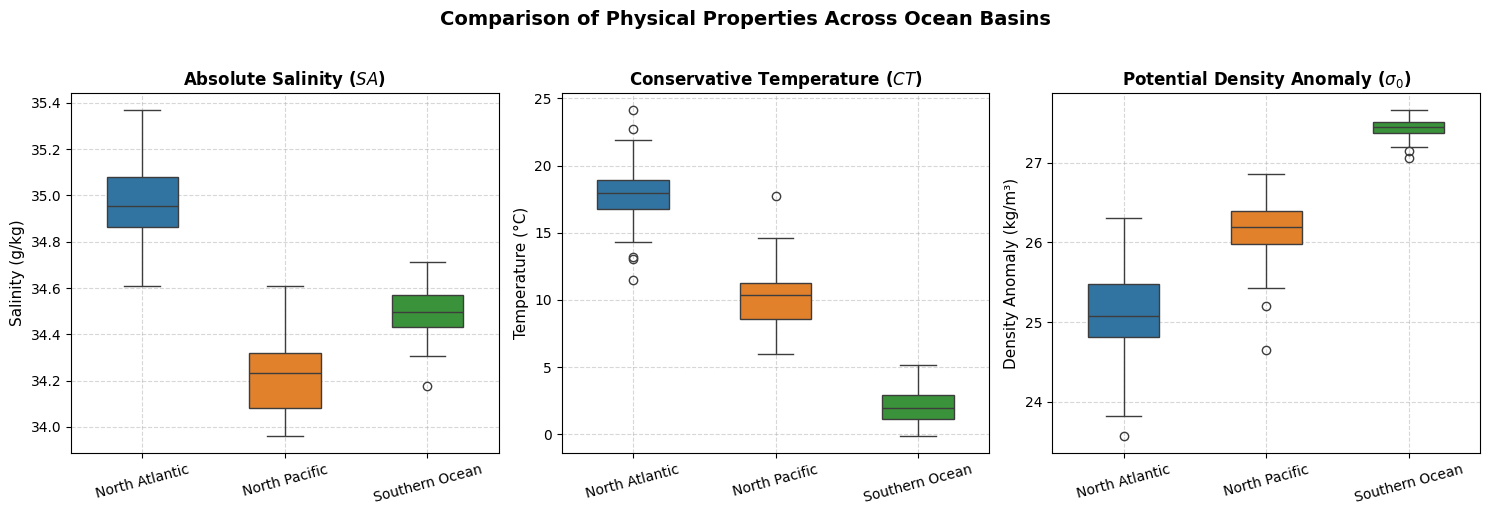

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# (Assuming 'df' DataFrame with SA, CT, Sigma0, and Basin columns from previous code)

# Set figure and subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)

# Custom palette for basins
palette = {'North Atlantic': '#1f77b4', 'North Pacific': '#ff7f0e', 'Southern Ocean': '#2ca02c'}

# 1. Absolute Salinity (SA)
sns.boxplot(ax=axes[0], data=df, x='Basin', y='SA', palette=palette, width=0.5)
axes[0].set_title('Absolute Salinity ($SA$)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Salinity (g/kg)', fontsize=11)
axes[0].set_xlabel('')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Conservative Temperature (CT)
sns.boxplot(ax=axes[1], data=df, x='Basin', y='CT', palette=palette, width=0.5)
axes[1].set_title('Conservative Temperature ($CT$)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Temperature (°C)', fontsize=11)
axes[1].set_xlabel('')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Density Anomaly (Sigma0)
sns.boxplot(ax=axes[2], data=df, x='Basin', y='Sigma0', palette=palette, width=0.5)
axes[2].set_title('Potential Density Anomaly ($\sigma_0$)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Density Anomaly (kg/m³)', fontsize=11)
axes[2].set_xlabel('')
axes[2].grid(True, linestyle='--', alpha=0.5)

# Rotate x-axis labels slightly for clarity
for ax in axes:
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Comparison of Physical Properties Across Ocean Basins', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

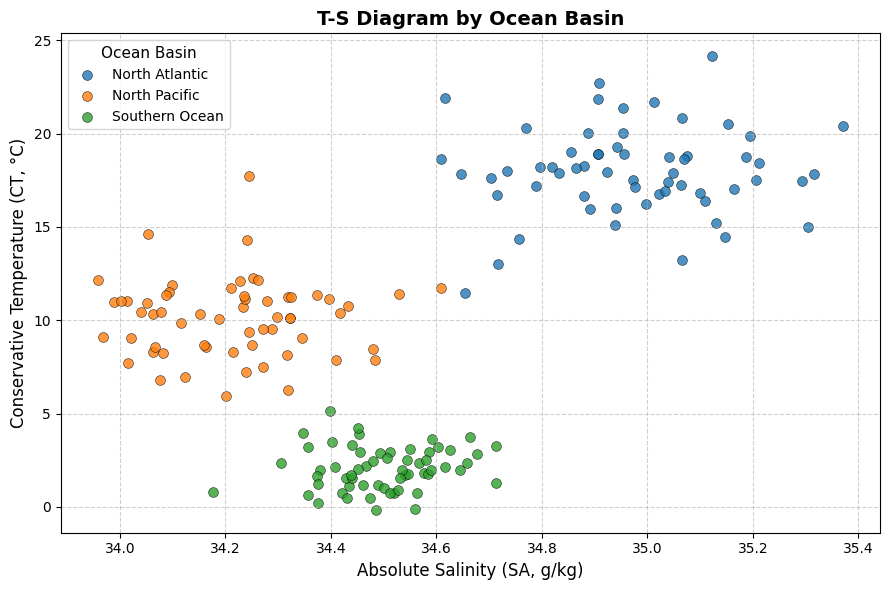

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create sample data spanning different ocean basins
np.random.seed(42)
n_points_per_basin = 60

data = []
basins = {
    'North Atlantic': {'sa_mean': 35.0, 'ct_mean': 18.0, 'sa_std': 0.2, 'ct_std': 2.5},
    'North Pacific':  {'sa_mean': 34.2, 'ct_mean': 10.0, 'sa_std': 0.15, 'ct_std': 2.0},
    'Southern Ocean': {'sa_mean': 34.5, 'ct_mean': 2.0,  'sa_std': 0.1,  'ct_std': 1.5}
}

for basin_name, params in basins.items():
    sa = np.random.normal(params['sa_mean'], params['sa_std'], n_points_per_basin)
    ct = np.random.normal(params['ct_mean'], params['ct_std'], n_points_per_basin)

    # Store in a temporary dataframe
    df_temp = pd.DataFrame({'SA': sa, 'CT': ct, 'Basin': basin_name})
    data.append(df_temp)

df = pd.concat(data, ignore_index=True)

# 2. Compute potential density anomaly using your function
df['Sigma0'] = sigmai_dep(df['CT'], df['SA'], p=0)

# 3. Create the Basin-Labeled T-S Diagram
plt.figure(figsize=(9, 6))

# Define distinct markers or colors for each basin
basin_colors = {
    'North Atlantic': '#1f77b4',  # Blue
    'North Pacific': '#ff7f0e',   # Orange
    'Southern Ocean': '#2ca02c'   # Green
}

for basin_name, color in basin_colors.items():
    subset = df[df['Basin'] == basin_name]
    plt.scatter(
        subset['SA'],
        subset['CT'],
        label=basin_name,
        color=color,
        alpha=0.8,
        s=50,
        edgecolor='k',
        linewidth=0.4
    )

# 4. Styling the plot
plt.xlabel('Absolute Salinity (SA, g/kg)', fontsize=12)
plt.ylabel('Conservative Temperature (CT, °C)', fontsize=12)
plt.title('T-S Diagram by Ocean Basin', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)

# Add a descriptive legend
plt.legend(title='Ocean Basin', fontsize=10, title_fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# read the data
option = "remote"

if option == "local":
    print("loading data locally (assumes file has already been downloaded)")
    path = "argo_csv.csv"
elif option == "remote":
    print("loading data remotely")
    path = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/argo_data.csv"
else:
    raise ValueError("INVALID OPTION: use 'remote' or 'local'")

df = pd.read_csv(path)
df
# subsetting data out by basin label, and loading these into numpy arrays
data_NA = df[df["basin"] == "N_Atlantic"]
TS_NA = data_NA[["temperature_degC", "salinity_g/kg"]].values
TS_NA
# density calculator: sigmai_dep(temperature, salinity)
dens_NA = sigmai_dep(TS_NA[:, 0], TS_NA[:, 1])
dens_NA